# Project Introduction

<b>Title : Marketing Campaign Subsription Analysis\
Dataset : [Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing)\
Tools : Python, Pandas, Tableau\
Output : Dashboard</b>

## Problem Statement
From this dataset, we want to identify customer profile (its age group, jobs, average balance) with its conversion rate & our campaign performace

These results can be presented to finance & marketing team to gain an better standing to its customers & get a better approach towards differents age group

## Background & Business Context
This Problem is important in the banking industry because different age group serve a different purpose in financial needs. For example: 

- **Younger customers** may prioritize on first-time mortgages, student loans, entry-level credit cards, and building financial foundation. These could be a potential long-term customer lifetime value

- **Older customers** typically will be focusing in retirement, savings, and invesment management

These differences create an opportunity for developing more suitable marketing strategies and relevant financial decisions.

# Import Libraries

In [1]:
import pandas as pd

# Data Loading

In [2]:
df_raw = pd.read_csv('bank.csv', delimiter=';')
df = df_raw.copy()

# Data Explore

In [3]:
missing_value = df.isna().sum().sum()
dupes = df.duplicated().sum()

print(f'Total missing value: {missing_value}')
print(f'Duplicate Rows : {dupes}')

Total missing value: 0
Duplicate Rows : 0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB


Data contains 16 Columns & 4521 Rows with no missing values and duplicate rows

## Check for hidden whitespaces

In [5]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='object')

All columns name are normal, e.g no hidden whitespaces

We change `y` into `deposit_sub`, since this dataset will be used for analysis, not for a model (`y` were the taget, for more info read `bank-names.txt`) 

In [6]:
df.rename(columns={'y' : 'deposit_sub'}, inplace=True)

In [7]:
df.columns

for i in df.columns:
    print(f'{i} unique values: {df[i].nunique()}')

age unique values: 67
job unique values: 12
marital unique values: 3
education unique values: 4
default unique values: 2
balance unique values: 2353
housing unique values: 2
loan unique values: 2
contact unique values: 3
day unique values: 31
month unique values: 12
duration unique values: 875
campaign unique values: 32
pdays unique values: 292
previous unique values: 24
poutcome unique values: 4
deposit_sub unique values: 2


In [8]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[18, 26, 35, 45, 54, 64, 120],
    labels=['Youth', 'Adult','Middle', 'Unc', 'Gramps', 'OG']
)

Age groups:

- Youth : 18-26
- Adult : 27-35
- Middle : 36-45
- Unc : 46-54
- Gramps : 55-64
- OG : 65-+

In [9]:
df[df['age'] >= 65]

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit_sub,age_group
27,67,retired,married,unknown,no,696,no,no,telephone,17,aug,119,1,105,2,failure,no,OG
30,68,retired,divorced,secondary,no,4189,no,no,telephone,14,jul,897,2,-1,0,unknown,yes,OG
36,78,retired,divorced,primary,no,229,no,no,telephone,22,oct,97,1,-1,0,unknown,yes,OG
129,77,retired,divorced,tertiary,no,4659,no,no,cellular,14,apr,161,1,-1,0,unknown,yes,OG
166,78,housemaid,married,secondary,no,499,no,no,telephone,16,mar,80,4,-1,0,unknown,no,OG
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4319,70,retired,divorced,secondary,no,6850,no,no,telephone,5,mar,252,3,183,1,failure,no,OG
4323,83,retired,divorced,primary,no,0,no,no,telephone,31,may,664,1,77,3,success,no,OG
4337,73,retired,married,unknown,no,519,no,no,telephone,16,oct,434,1,57,1,failure,yes,OG
4388,83,retired,divorced,primary,no,1097,no,no,telephone,5,mar,181,1,-1,0,unknown,yes,OG


Columns `marital`, `education`, `default`, `housing`, `loan`, `contact`, `poutcome`, `deposit_sub` has a small number of unique values, we will investigate does these columns value represents a ordinal value?

In [10]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit_sub,age_group
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no,Adult
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no,Adult
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no,Adult
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no,Adult
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no,Gramps


# Column information

## Input variables:
   ### bank client data:
   1 - age (numeric)\
   2 - job : type of job (categorical: "admin.","unknown","unemployed","management","housemaid","entrepreneur","student","blue-collar","self-employed","retired","technician","services")\
   3 - marital : marital status (categorical: "married","divorced","single"; note: "divorced" means divorced or widowed)
   4 - education (categorical: "unknown","secondary","primary","tertiary")\
   5 - default: has credit in default? (binary: "yes","no")\
   6 - balance: average yearly balance, in euros (numeric)\
   7 - housing: has housing loan? (binary: "yes","no")\
   8 - loan: has personal loan? (binary: "yes","no")
   
   ### related with the last contact of the current campaign:
   9 - contact: contact communication type (categorical: "unknown","telephone","cellular")\
  10 - day: last contact day of the month (numeric)\
  11 - month: last contact month of year (categorical: "jan", "feb", "mar", ..., "nov", "dec")\
  12 - duration: last contact duration, in seconds (numeric)
   ### other attributes:
  13 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)\
  14 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric, -1 means client was not previously contacted)\
  15 - previous: number of contacts performed before this campaign and for this client (numeric)\
  16 - poutcome: outcome of the previous marketing campaign (categorical: "unknown","other","failure","success")\
  17 - deposit_sub - has the client subscribed a term deposit? (binary: "yes","no")

# Summary during pre-processing

By current process, here's an quick list of what we have done:

- Load raw data and make a copy for processing (having a raw data file could be useful for preservation and flexibility for changes)
- Checking missing values, resulted in 0
- Checking duplicate rows, resulted in 0
- Check for non-normalized column name
- Normalize columns name
- Get an understanding about each columns

We can continue to EDA (Exploratory Data Analysis)

# EDA

In [11]:
df_eda = df.copy()
df_eda.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit_sub,age_group
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no,Adult
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no,Adult
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no,Adult
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no,Adult
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no,Gramps


In [12]:
df_eda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   age          4521 non-null   int64   
 1   job          4521 non-null   object  
 2   marital      4521 non-null   object  
 3   education    4521 non-null   object  
 4   default      4521 non-null   object  
 5   balance      4521 non-null   int64   
 6   housing      4521 non-null   object  
 7   loan         4521 non-null   object  
 8   contact      4521 non-null   object  
 9   day          4521 non-null   int64   
 10  month        4521 non-null   object  
 11  duration     4521 non-null   int64   
 12  campaign     4521 non-null   int64   
 13  pdays        4521 non-null   int64   
 14  previous     4521 non-null   int64   
 15  poutcome     4521 non-null   object  
 16  deposit_sub  4521 non-null   object  
 17  age_group    4521 non-null   category
dtypes: category(1), int64(7), ob

## EDA: Customer Balance Analysis

In [13]:
df_eda['balance'].describe()

count     4521.000000
mean      1422.657819
std       3009.638142
min      -3313.000000
25%         69.000000
50%        444.000000
75%       1480.000000
max      71188.000000
Name: balance, dtype: float64

In [14]:
df.balance.skew()

6.596430546295735

In [15]:
balance_q1 = df.balance.quantile(0.25)
balance_q3 = df.balance.quantile(0.75)

iqr = balance_q3 - balance_q1

balance_up = balance_q3 + (iqr*3)
balance_down = balance_q1 - (iqr*3)
# iqr * 3 since our data has a extreme skew

print('IQR: ', iqr)
print('Upper boundary:', balance_up)
print('Lower boundary:', balance_down)


IQR:  1411.0
Upper boundary: 5713.0
Lower boundary: -4164.0


In [16]:
((df_eda['balance'] > balance_down) & (df_eda['balance'] < balance_up)).value_counts()

balance
True     4266
False     255
Name: count, dtype: int64

`255` Customers had an balance that exceed the upper bound

In [26]:
df_eda[df_eda['balance'] > balance_up]

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit_sub,age_group
10,39,services,married,secondary,no,9374,yes,no,unknown,20,may,273,1,-1,0,unknown,no,Middle
25,41,management,married,tertiary,no,5883,no,no,cellular,20,nov,182,2,-1,0,unknown,no,Middle
40,38,management,single,tertiary,no,11971,yes,no,unknown,17,nov,609,2,101,3,failure,no,Middle
62,48,management,married,tertiary,no,5887,no,no,cellular,13,aug,227,2,-1,0,unknown,no,Unc
64,56,admin.,married,secondary,no,16873,no,no,cellular,7,oct,223,1,-1,0,unknown,no,Gramps
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4440,45,blue-collar,married,primary,no,13117,no,no,unknown,11,jun,42,2,-1,0,unknown,no,Middle
4441,38,management,married,tertiary,no,12877,no,no,unknown,17,jun,118,3,-1,0,unknown,no,Middle
4451,55,management,married,tertiary,no,6880,no,no,cellular,8,aug,353,2,-1,0,unknown,no,Gramps
4457,37,blue-collar,single,primary,no,6969,yes,no,unknown,20,may,412,1,-1,0,unknown,no,Middle


Data was extremely skewed, with a few hints:

- Min and max value has a huge gap, ranging between -3313 (possibly a user in debt) to 71188
- high STD of 3009
- Mean was higher than median

We can conclude that the has a right-skewed distribution, with a lot of observation exceeding the upper boundary, while none fo it exceeding the lower boundary

By above information, we know information about our recorded clients:

- Most users have a low-to-mid balance
- Some users have exceptionally very high balance

In [33]:
df_eda[df_eda['balance'] > balance_up]['job'].value_counts()

job
management       81
technician       45
blue-collar      33
retired          23
services         15
admin.           13
housemaid        12
entrepreneur     10
self-employed     9
student           8
unemployed        3
unknown           3
Name: count, dtype: int64

In [34]:
df_eda[df_eda['balance'] > balance_up]['age_group'].value_counts()

age_group
Middle    86
Adult     66
Unc       47
Gramps    35
OG        14
Youth      7
Name: count, dtype: int64

From both tables, we can say customers that has a high balance are dominated by middle-aged, adult, and unc's from the age group while a small number of youths observed having a high balance. And customers that has a high balance typically worked in the management industries, technician or a blue collar workers

## EDA: Customer Segmentation & Subscription Rate Analysis

<Axes: title={'center': 'Client by age group'}>

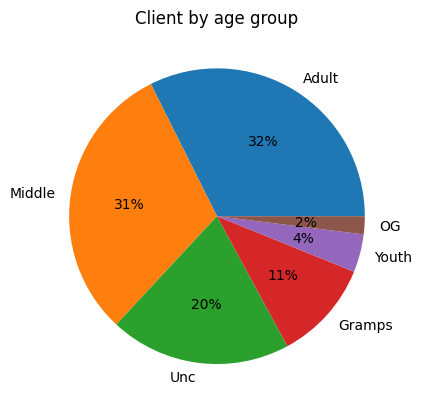

In [18]:
df_eda.age_group.value_counts().plot(kind='pie', ylabel='', title='Client by age group', autopct='%1.0f%%')

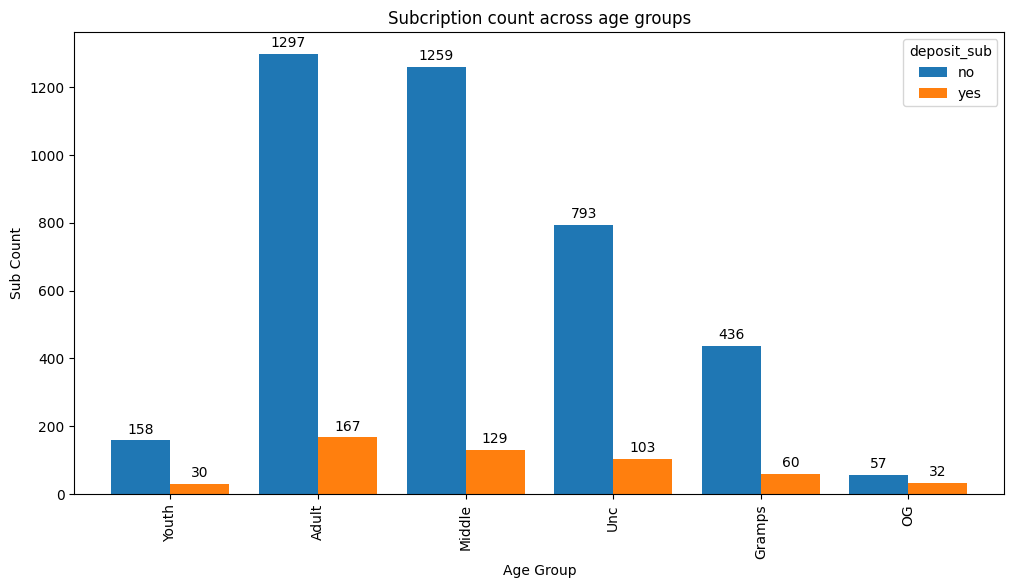

In [19]:
# - Check which age group subscribed a deposit term

customer_segment = pd.crosstab(
    df_eda['age_group'],
    df_eda['deposit_sub']
)

ax = customer_segment.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8,
    xlabel='Age Group',
    ylabel='Sub Count',
    title='Subcription count across age groups'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3)


In [20]:
sub = df_eda[df_eda['deposit_sub'] == 'yes']['age_group'].value_counts()

print(f'Client subbed: {sub.sum()}')
print(f'Non-subbed Client: {len(df_eda) - sub.sum()}\n')
for group, sub_count in sub.items():
    print(f'Subscription rate for {group}: {((sub_count/len(df_eda)) * 100):.2f}%')

print(f'\nTotal Subcription Conversion Rate: {((sub.sum()/len(df_eda)) * 100):.2f}%') 

Client subbed: 521
Non-subbed Client: 4000

Subscription rate for Adult: 3.69%
Subscription rate for Middle: 2.85%
Subscription rate for Unc: 2.28%
Subscription rate for Gramps: 1.33%
Subscription rate for OG: 0.71%
Subscription rate for Youth: 0.66%

Total Subcription Conversion Rate: 11.52%


## EDA: Campaign Effectiveness

In [21]:
campaign_effectiveness = df_eda.groupby('campaign').agg(
    customers=('deposit_sub', 'count'),
    subscribers=('deposit_sub', lambda x: (x == 'yes').sum())
)

campaign_effectiveness['conversion_rate'] = (
    campaign_effectiveness['subscribers']
    / campaign_effectiveness['customers'] * 100
)

campaign_effectiveness

,customers,subscribers,conversion_rate
campaign,,,
1,1734,240,13.840830
2,1264,138,10.917722
3,558,57,10.215054
4,325,43,13.230769
5,167,9,5.389222
6,155,16,10.322581
7,75,6,8.000000
8,56,4,7.142857
9,30,2,6.666667


<Axes: title={'center': 'Conversion Rate by Campaign Contact Frequency'}, xlabel='Number of Contacts', ylabel='Conversion Rate (%)'>

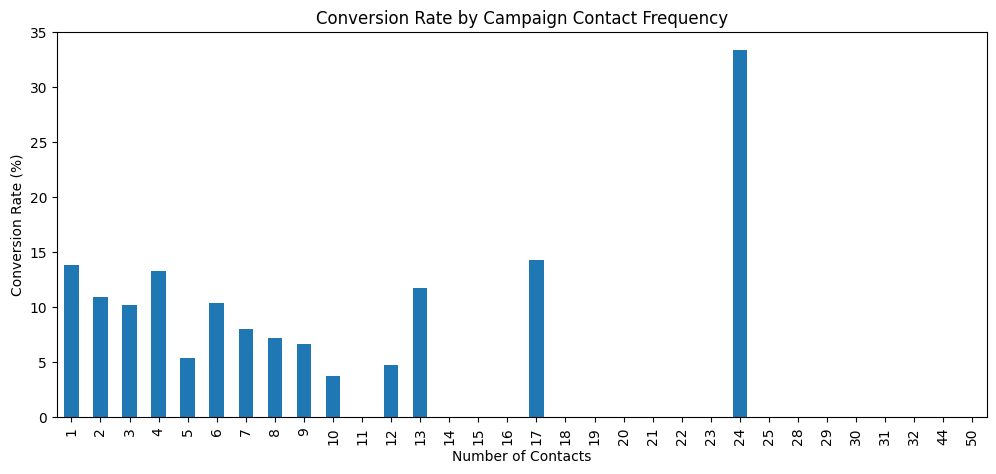

In [22]:
campaign_effectiveness['conversion_rate'].plot(
    kind='bar',
    figsize=(12, 5),
    xlabel='Number of Contacts',
    ylabel='Conversion Rate (%)',
    title='Conversion Rate by Campaign Contact Frequency'
)

Number `24` has an unusual convert rate of `33.3%`, this number is high due to low customer and subscribers, `3` customers with `1` subsription, resulting in `33.3%`

In [23]:
previous_effectiveness = pd.crosstab(
    df_eda['poutcome'],
    df_eda['deposit_sub'],
    normalize='index'
) * 100

previous_effectiveness

deposit_sub,no,yes
poutcome,,
failure,87.142857,12.857143
other,80.710660,19.289340
success,35.658915,64.341085
unknown,90.904184,9.095816


<Axes: title={'center': 'Subscription Distribution by Previous Campaign Outcome'}, xlabel='poutcome', ylabel='Percentage (%)'>

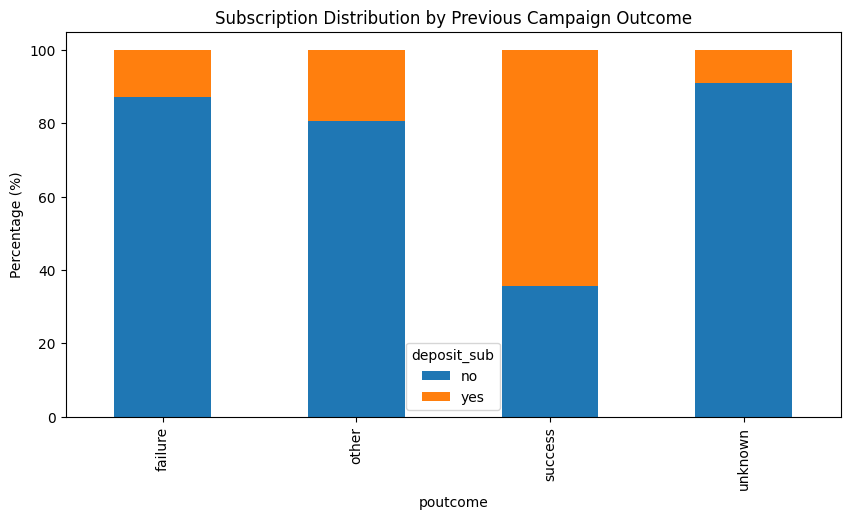

In [24]:
previous_effectiveness.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5),
    ylabel='Percentage (%)',
    title='Subscription Distribution by Previous Campaign Outcome'
)

# Conclusion

From our EDA, we find:

- Customers age group & and its average balance
- High balance customers job profile
- Conversion rate of 11.52%
- Our campaign effectiveness towards different contact performed

# Action

- Adjust targeted marketing towards different age groups
    - Develop a different marketing approach based on customer demographics, job, and subscription behavior
    - Identify Age group with higher subscription rate and investigate which approach are suitable to each age group
- Investigate how we could improve our conversion rate
    - Evaluate different communication methods and does its have an impact towards a succesfull campaign
    - Monitor conversion rates towards different customer segments
- Encourage customer retention and long-term contract
    - Develop customer engagement that can maintain relationship with existing customess
    - Explore oppurtunities to increase customer lifetime values